In [1]:
# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.impute import SimpleImputer

print("Libraries imported successfully.")


Libraries imported successfully.


## 2. LOAD THE  DATASET




In [3]:
# ============================================================
# 2. LOAD DATASET
# ============================================================

df = pd.read_csv(
    r'C:\\Users\\User\\Downloads\\heart+disease\\heart_disease_combined_raw(3).csv'
)

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (900, 77)


,source,id,ccf,age,sex,painloc,painexer,relrest,pncaden,cp,...,rcaprox,rcadist,lvx1,lvx2,lvx3,lvx4,lvf,cathef,junk,name
0,Cleveland,1,0,63,1,-9,-9,-9,-9,1,...,1,1,1,1,1,1,1,-9.0,-9.0,name
1,Cleveland,2,0,67,1,-9,-9,-9,-9,4,...,1,1,1,1,1,1,1,-9.0,-9.0,name
2,Cleveland,3,0,67,1,-9,-9,-9,-9,4,...,2,2,1,1,1,7,3,-9.0,-9.0,name
3,Cleveland,4,0,37,1,-9,-9,-9,-9,3,...,1,1,1,1,1,1,1,-9.0,-9.0,name
4,Cleveland,6,0,41,0,-9,-9,-9,-9,2,...,1,1,1,1,1,1,1,-9.0,-9.0,name


## 3. BASIC DATASET UNDERSTANDING

Before preprocessing, check the number of rows, columns, data types and duplicate records.


In [3]:
# ============================================================
# 3. BASIC INSPECTION
# ============================================================

print("Shape:", df.shape)

print("\nData types:")
print(df.dtypes)

print("\nDuplicate rows:", df.duplicated().sum())


Shape: (900, 77)

Data types:
source        str
id          int64
ccf         int64
age         int64
sex         int64
           ...   
lvx4        int64
lvf         int64
cathef    float64
junk      float64
name          str
Length: 77, dtype: object

Duplicate rows: 0


## 4. REMOVE DUPLICATE ROWS

Duplicate records can give the same student information more influence during model training.

We remove exact duplicate rows before creating the train/test sets.


In [4]:


rows_before = len(df)

df = df.drop_duplicates().reset_index(drop=True)

rows_after = len(df)

print("Rows before removing duplicates:", rows_before)
print("Rows after removing duplicates :", rows_after)
print("Duplicates removed             :", rows_before - rows_after)


Rows before removing duplicates: 900
Rows after removing duplicates : 900
Duplicates removed             : 0


## 5. SEPARATE FEATURES (X) AND TARGET (y)

`X` contains the input features.

`y` contains the value that we want to predict.

For this dataset, the target is `PlacementStatus`.

The target must **not** be imputed or scaled as an input feature.


In [5]:
import pandas as pd

df = pd.read_csv(
    r'C:\Users\User\Downloads\heart+disease\heart_disease_combined_raw.csv'
)

X = df.drop("num", axis=1)
y = df["num"]

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

X shape: (900, 76)
y shape: (900,)

Target distribution:
num
0     404
1     191
3     132
2     130
4      42
80      1
Name: count, dtype: int64


# 6. TRAIN/TEST SPLIT — BEFORE PREPROCESSING

This step must come **before** imputation, encoding and scaling.

Why?

Because the test set represents unseen future data.

We must not use test data to calculate:

- median values
- category mappings
- means
- standard deviations
- minimum/maximum values

This prevents **data leakage**.


In [6]:
print(y.value_counts())
print("\nUnique values:")
print(y.unique())


print("X shape:", X.shape)
print("y shape:", y.shape)
y = (df["num"] > 0).astype(int)

X = df.drop("num", axis=1)

print("Target distribution:")
print(y.value_counts())
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows :", len(X_test))
print("Training percentage:", len(X_train) / len(X) * 100)
print("Testing percentage :", len(X_test) / len(X) * 100)

num
0     404
1     191
3     132
2     130
4      42
80      1
Name: count, dtype: int64

Unique values:
[ 0  2  1  3  4 80]
X shape: (900, 76)
y shape: (900,)
Target distribution:
num
1    496
0    404
Name: count, dtype: int64
Training rows: 720
Testing rows : 180
Training percentage: 80.0
Testing percentage : 20.0


# 7. IDENTIFY NUMERICAL AND CATEGORICAL FEATURES

We separate the columns because different types of data need different preprocessing.

**Numerical features:** CGPA, attendance, internships, etc.

**Categorical features:** Gender, City, Stream, Specialisation, etc.


In [7]:

import numpy as np

numeric_cols = X_train.select_dtypes(include=np.number).columns.tolist()

categorical_cols = X_train.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical columns:", len(numeric_cols))
print(numeric_cols)

print("\nCategorical columns:", len(categorical_cols))
print(categorical_cols)

Numerical columns: 70
['id', 'ccf', 'age', 'sex', 'painloc', 'painexer', 'relrest', 'pncaden', 'cp', 'trestbps', 'htn', 'chol', 'smoke', 'cigs', 'fbs', 'dm', 'famhist', 'restecg', 'ekgmo', 'ekgyr', 'dig', 'prop', 'nitr', 'pro', 'proto', 'thaldur', 'thaltime', 'met', 'thalach', 'thalrest', 'tpeakbps', 'tpeakbpd', 'dummy', 'trestbpd', 'exang', 'xhypo', 'oldpeak', 'slope', 'rldv5', 'rldv5e', 'ca', 'restckm', 'exerckm', 'restef', 'restwm', 'exeref', 'exerwm', 'thal', 'thalsev', 'thalpul', 'earlobe', 'cday', 'cyr', 'lmt', 'ladprox', 'laddist', 'diag', 'cxmain', 'ramus', 'om1', 'om2', 'rcaprox', 'rcadist', 'lvx1', 'lvx2', 'lvx3', 'lvx4', 'lvf', 'cathef', 'junk']

Categorical columns: 6
['source', 'years', 'ekgday', 'diuretic', 'cmo', 'name']


# 8. MISSING-VALUE AUDIT

The slides identify five important PlacementPredict features with missing values:

- `MockInterviewScore`
- `Workshops`
- `AptitudeTestScore`
- `SoftSkillsRating`
- `CodingTestScore`

We calculate missingness using **X_train only**.


In [8]:
# ============================================================
# 8. MISSING VALUE ANALYSIS
# ============================================================

missing_count = X_train.isna().sum()
missing_percent = X_train.isna().mean() * 100

missing_summary = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing %": missing_percent
})

missing_summary = missing_summary[
    missing_summary["Missing Count"] > 0
].sort_values("Missing %", ascending=False)

display(missing_summary)

,Missing Count,Missing %


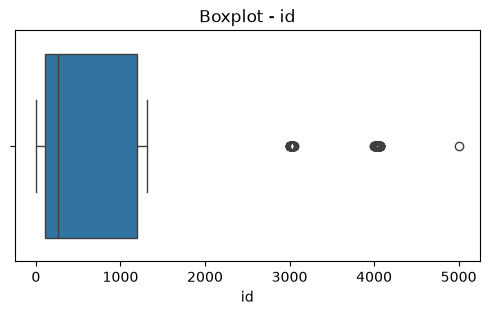

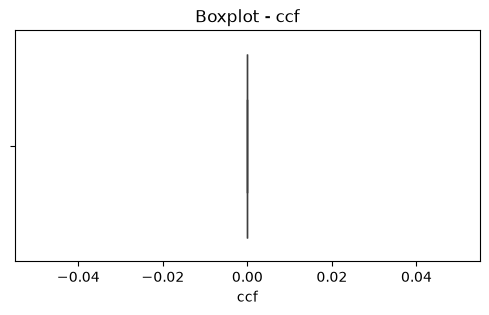

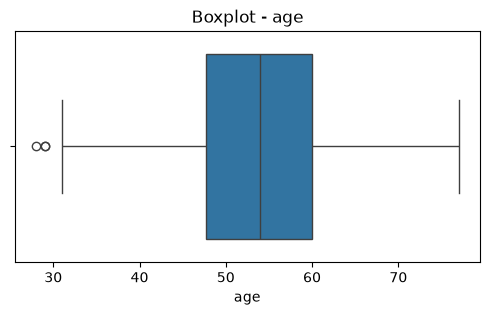

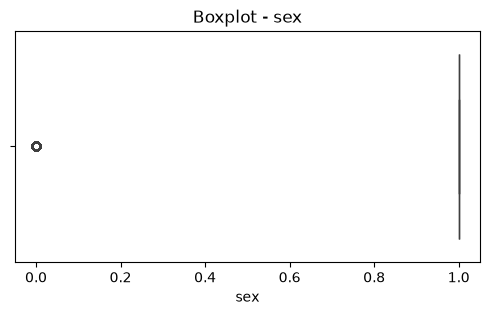

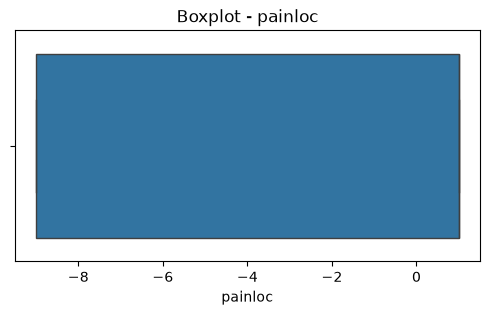

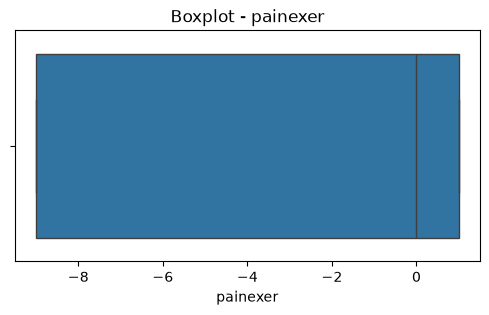

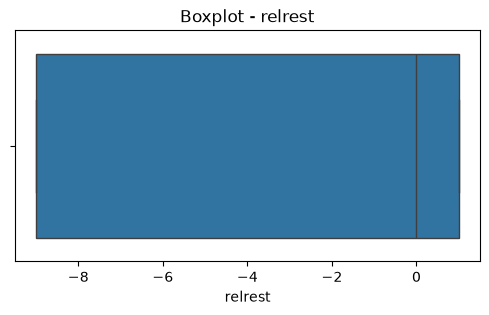

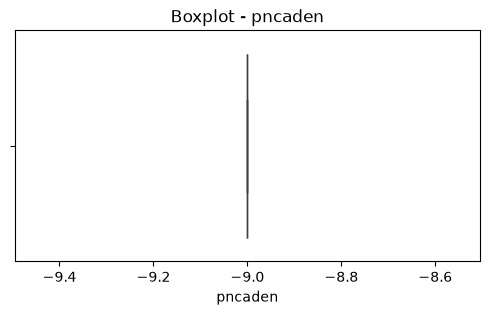

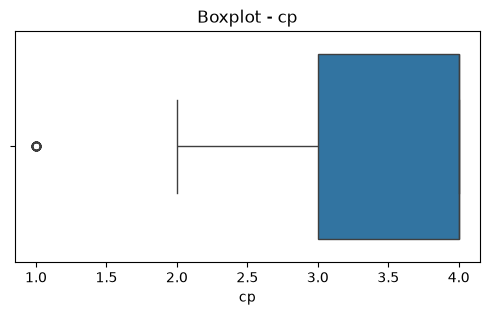

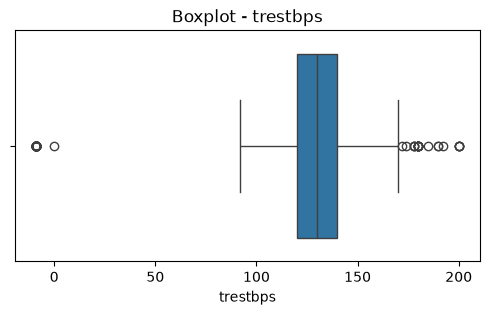

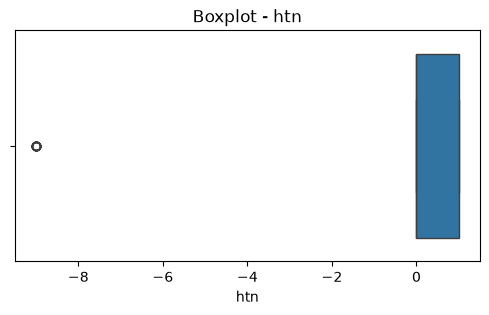

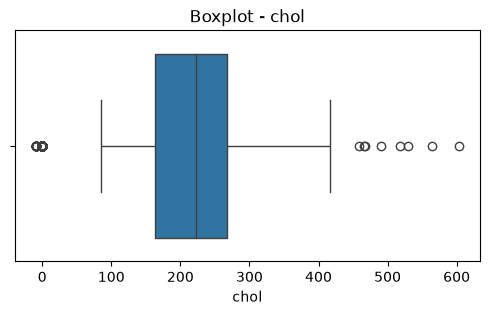

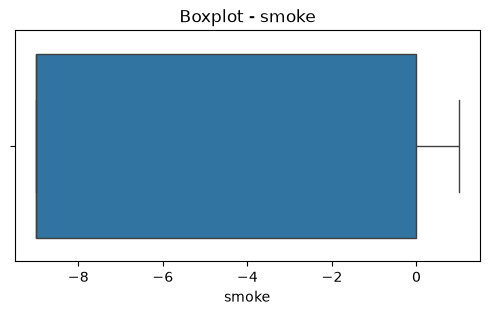

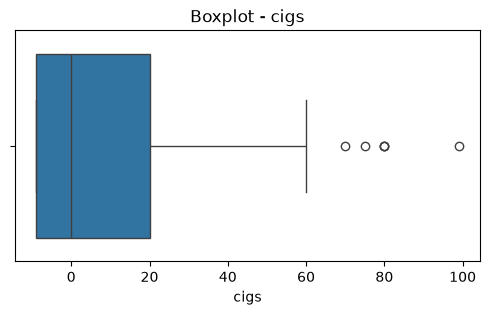

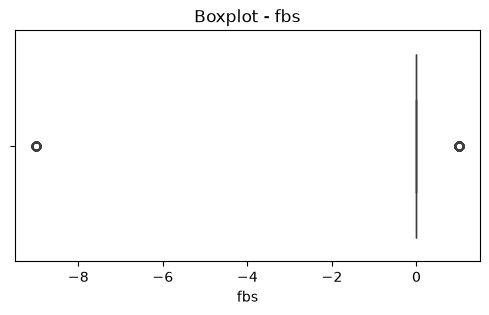

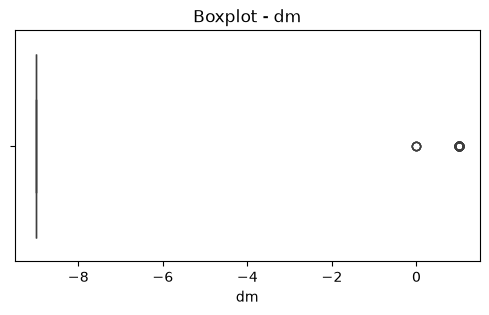

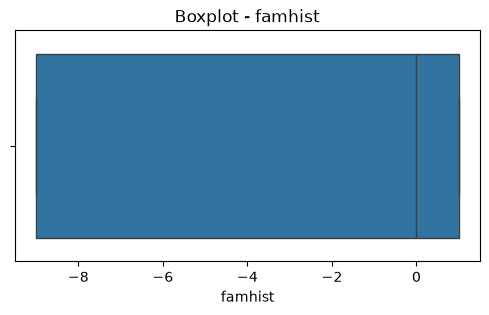

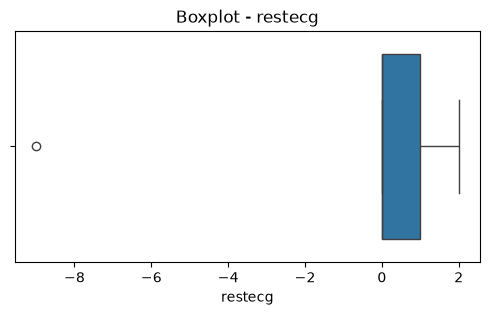

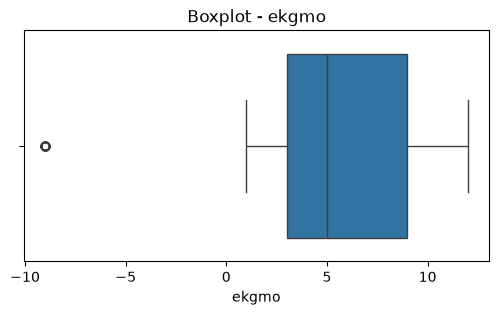

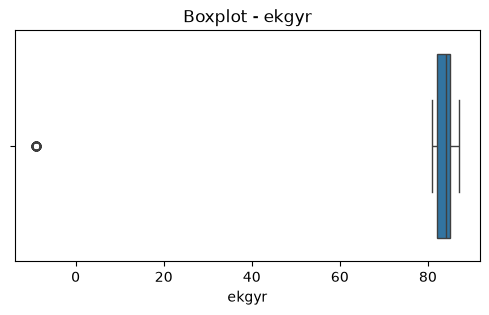

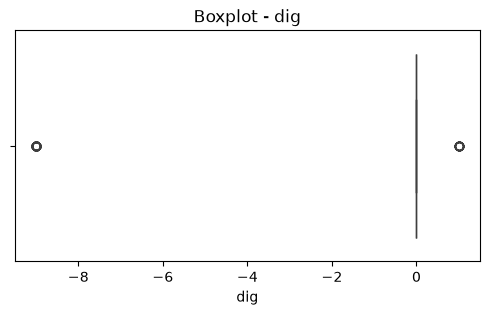

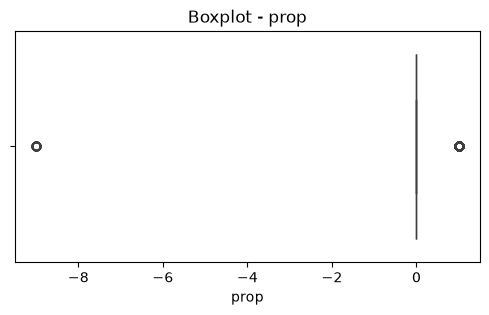

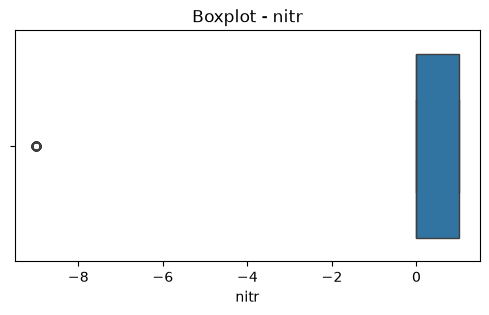

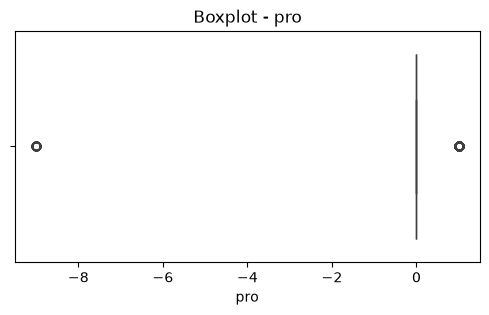

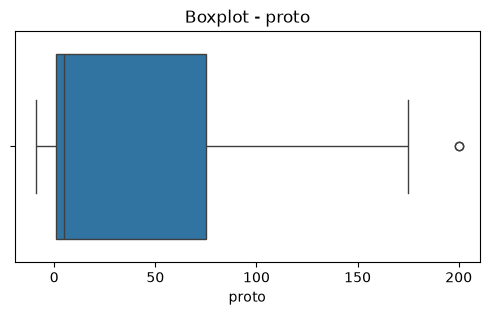

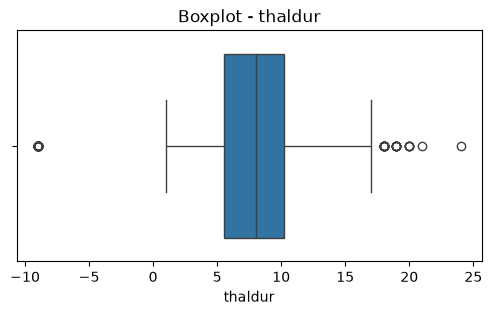

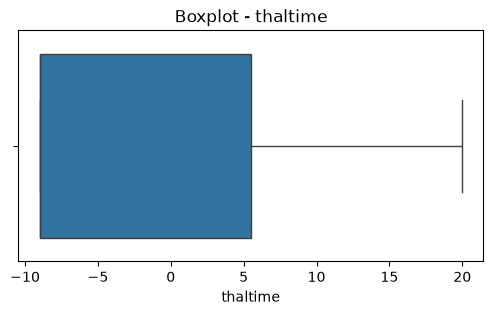

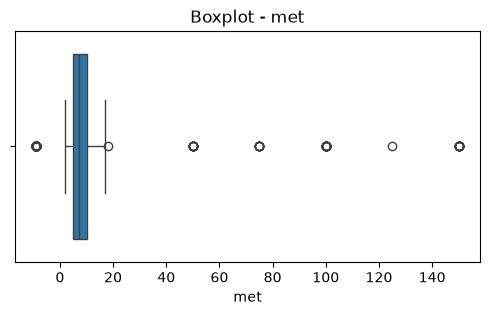

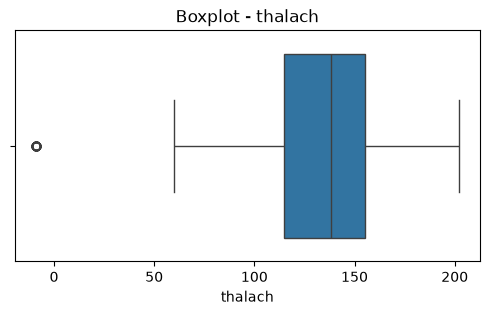

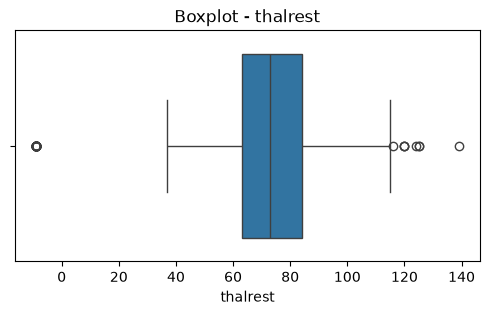

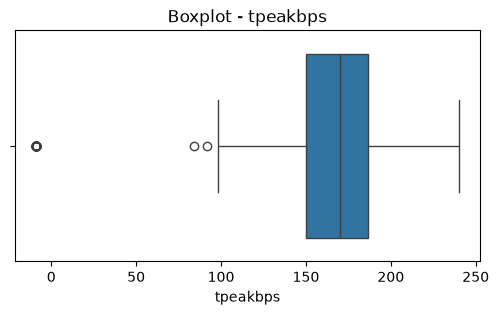

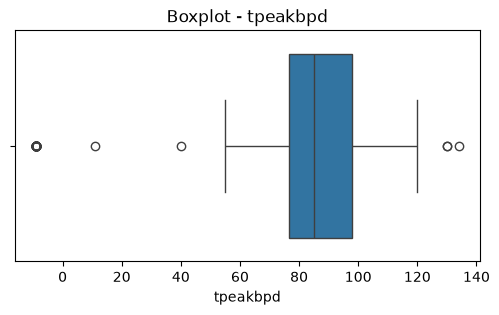

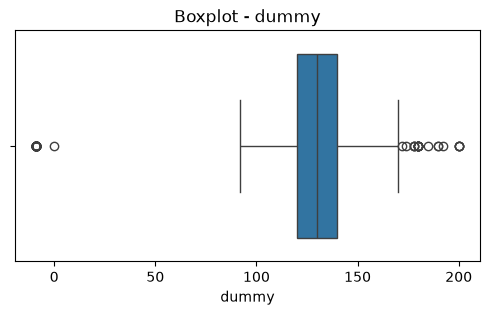

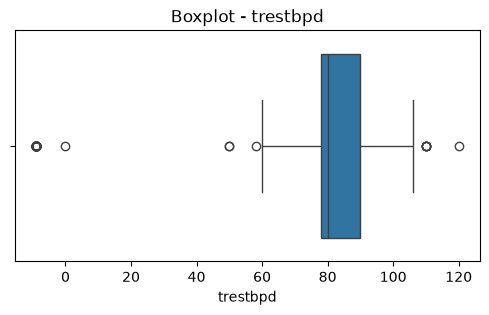

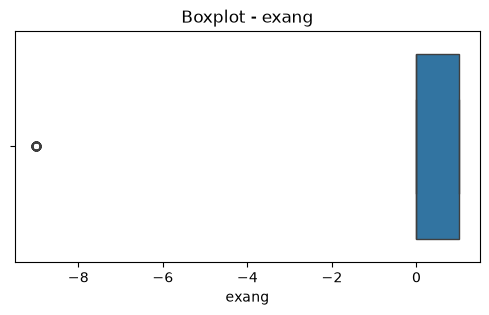

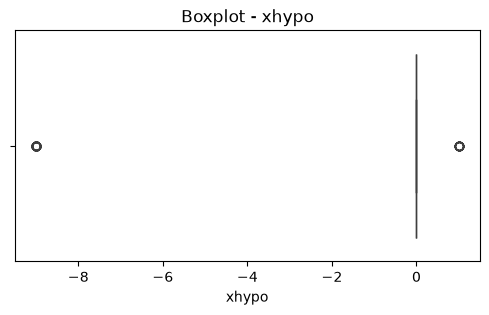

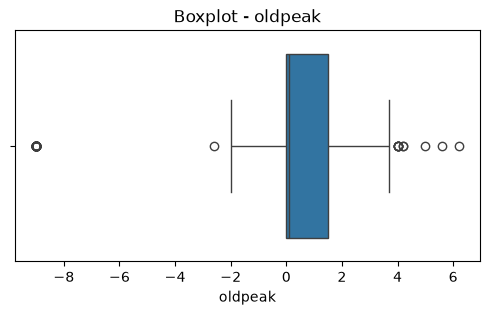

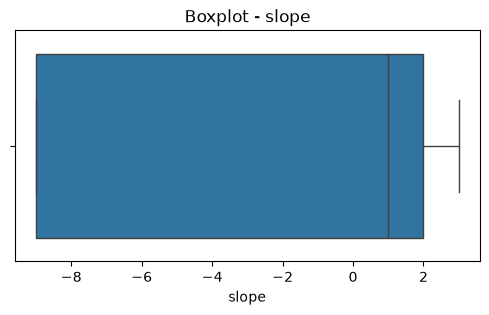

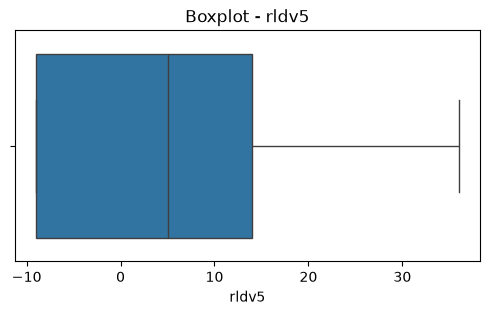

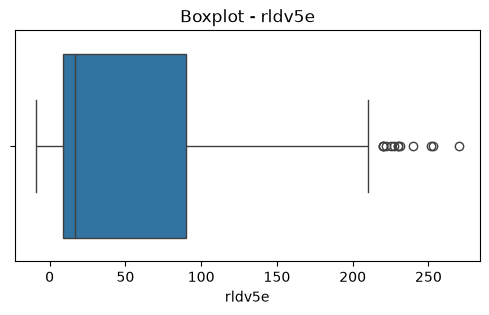

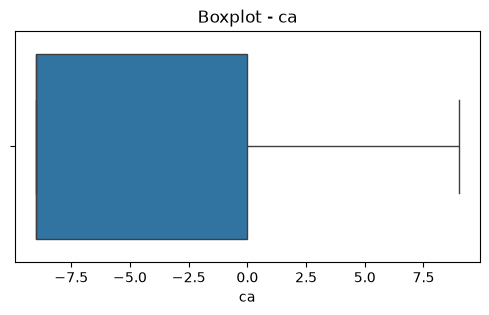

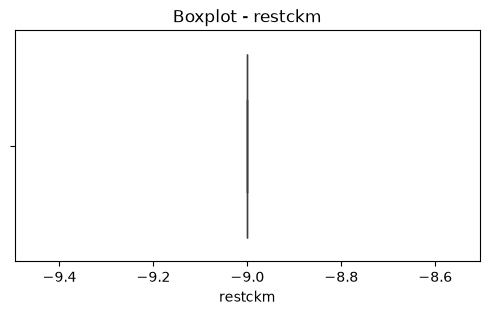

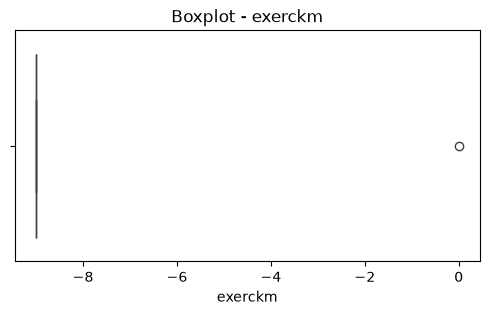

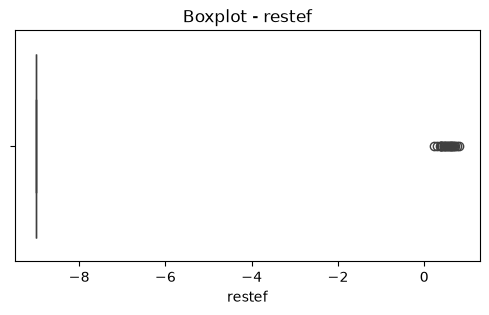

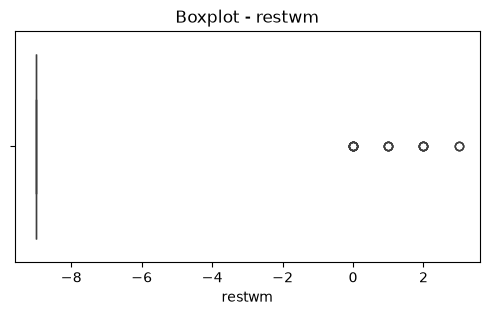

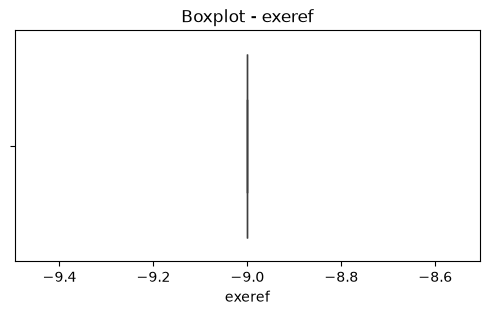

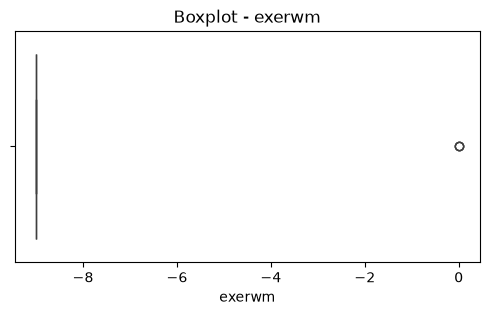

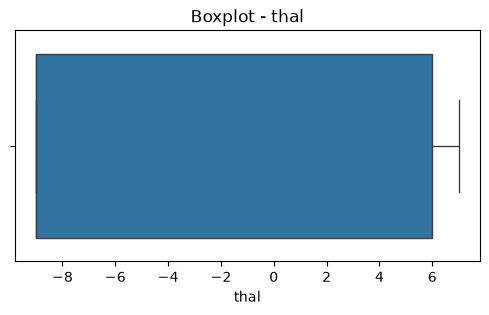

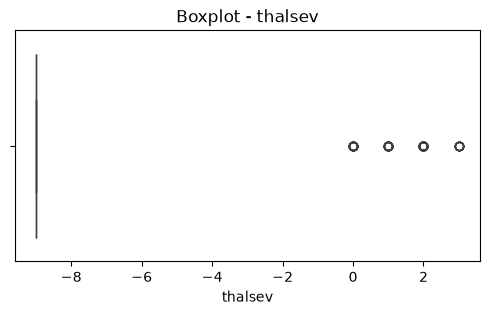

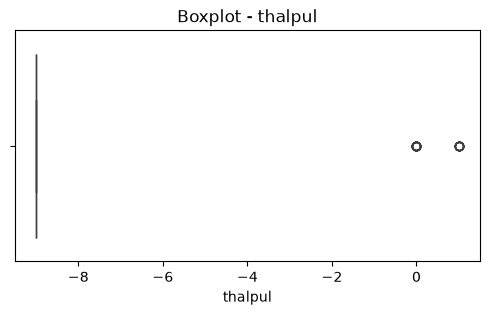

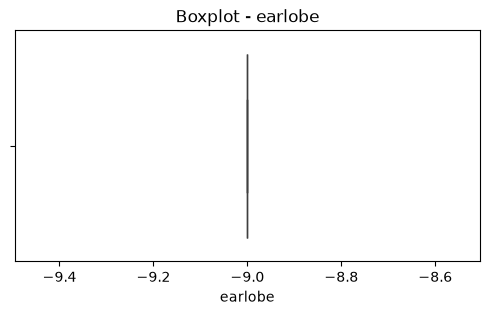

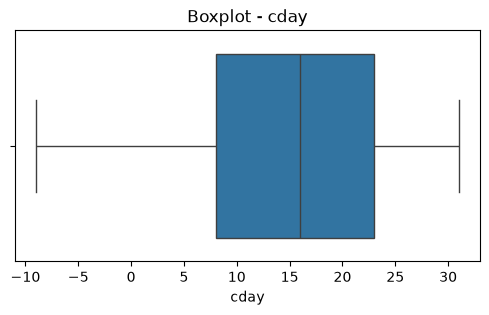

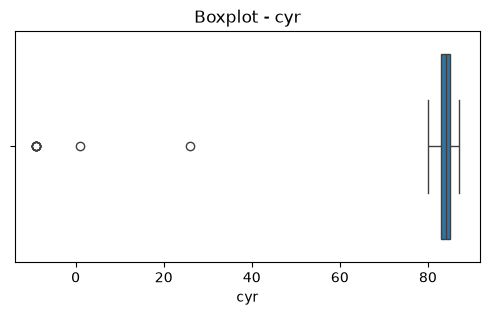

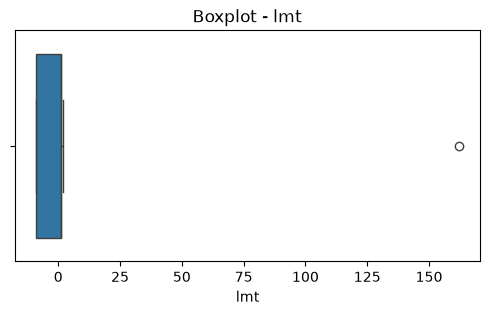

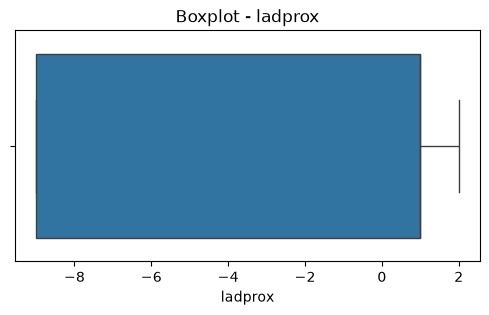

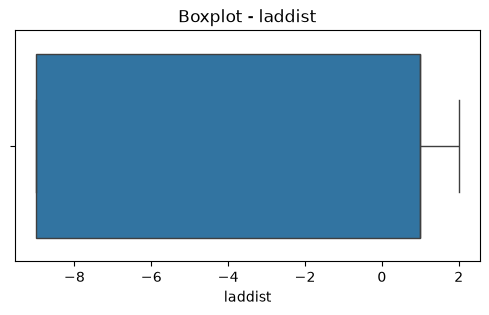

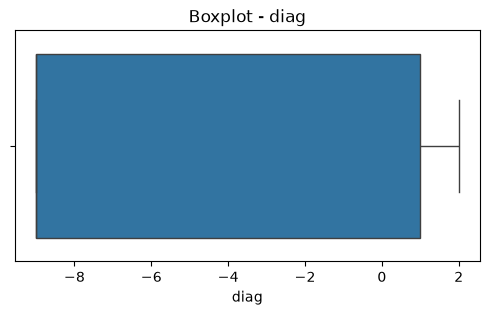

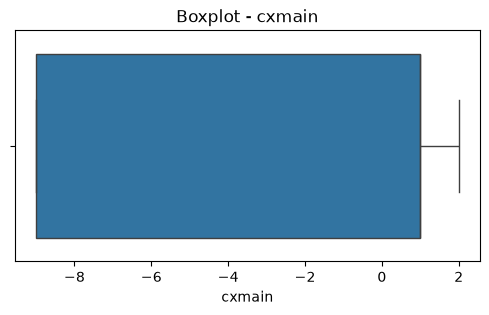

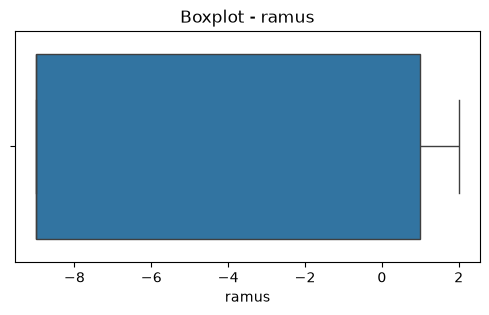

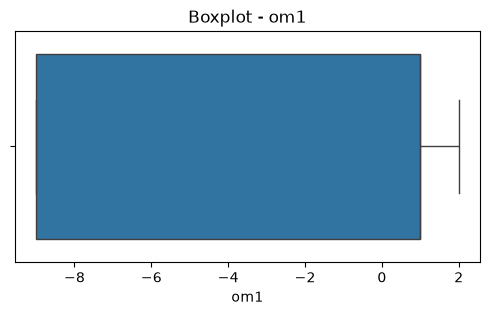

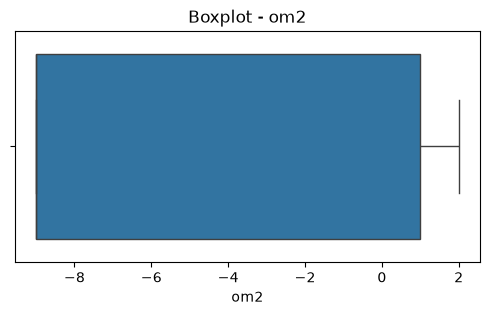

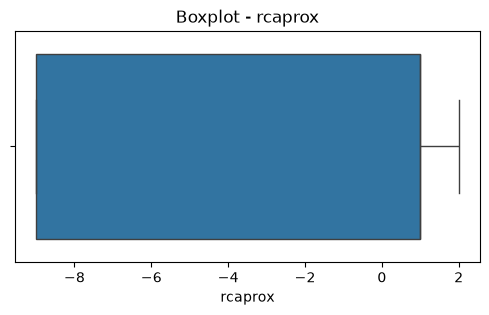

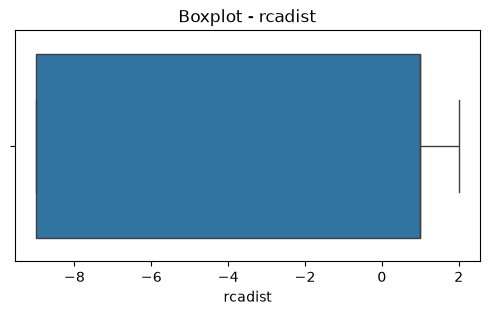

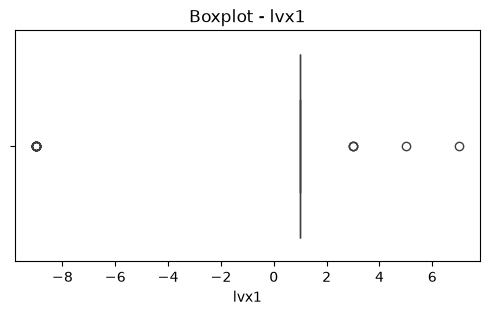

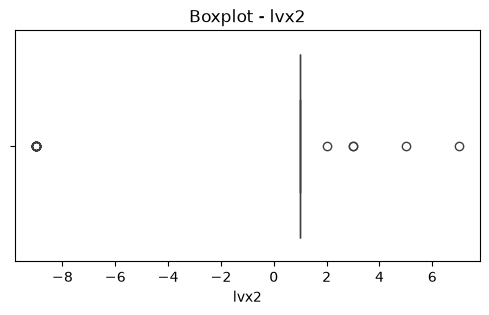

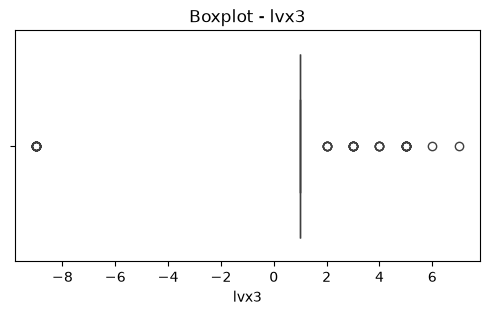

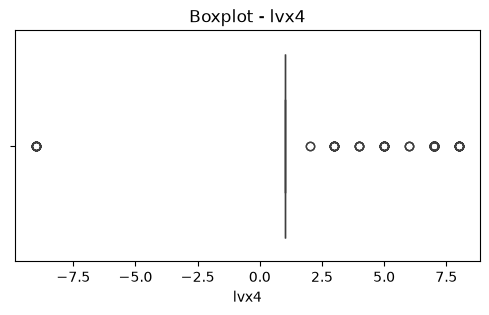

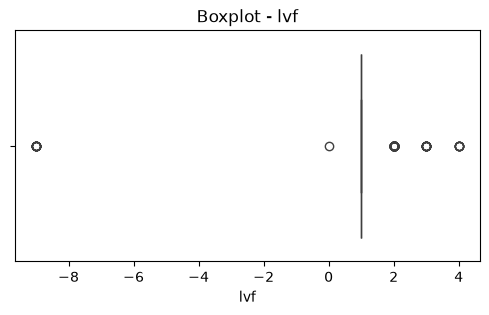

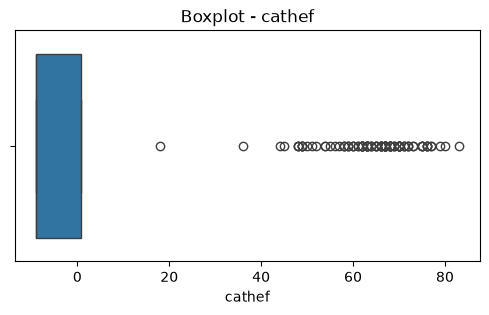

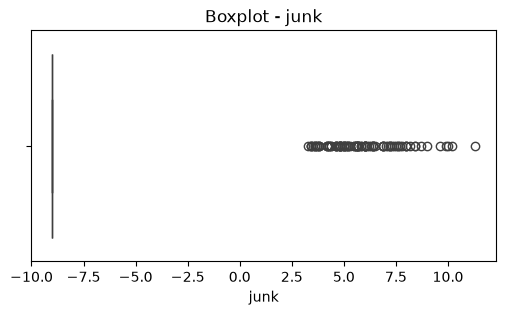

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

for col in numeric_cols:

    plt.figure(figsize=(6, 3))

    sns.boxplot(x=X_train[col])

    plt.title("Boxplot - " + col)
    plt.xlabel(col)

    plt.show()

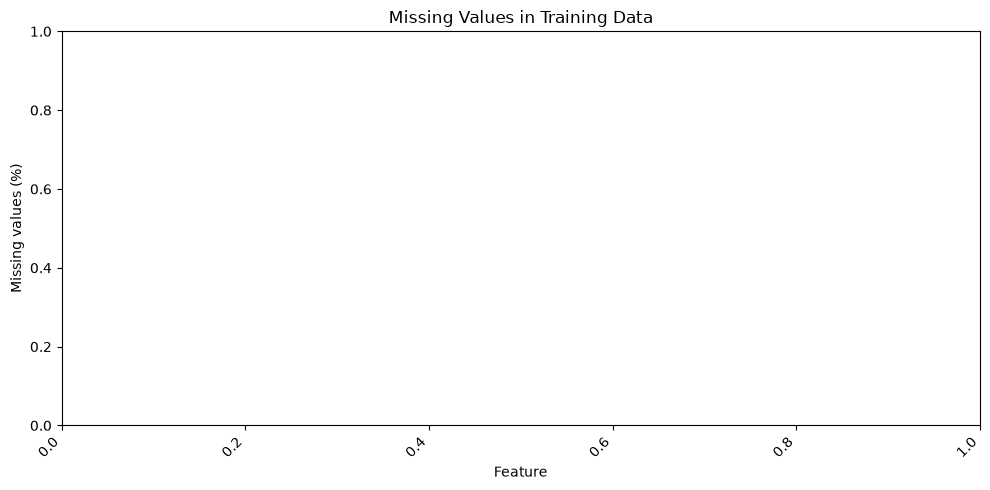

In [10]:
# ============================================================
# 8A. MISSING-VALUE VISUALIZATION
# ============================================================

plt.figure(figsize=(10, 5))

sns.barplot(
    x=missing_summary.index,
    y=missing_summary["Missing %"]
)

plt.xticks(rotation=45, ha="right")
plt.xlabel("Feature")
plt.ylabel("Missing values (%)")
plt.title("Missing Values in Training Data")
plt.tight_layout()
plt.show()

# 9. CHECK THE EFFECT OF ROW DELETION

Before choosing deletion, measure how many training rows would be lost.

If a large percentage of students are removed, imputation is usually preferable.

The slides show that listwise deletion can result in substantial data loss for this dataset.

## NOTE: We are not deleting actually 

In [11]:
# ============================================================
# 9. LISTWISE DELETION CHECK
# ============================================================

rows_before = len(X_train)

X_train_without_missing = X_train.dropna()

rows_after = len(X_train_without_missing)

loss = rows_before - rows_after
loss_percent = loss / rows_before * 100

print("Rows before deletion:", rows_before)
print("Rows after deletion :", rows_after)
print("Rows lost           :", loss)
print("Percentage lost     :", round(loss_percent, 2), "%")

Rows before deletion: 720
Rows after deletion : 720
Rows lost           : 0
Percentage lost     : 0.0 %


In [36]:
X_train

,source,id,ccf,age,sex,painloc,painexer,relrest,pncaden,cp,...,rcaprox,rcadist,lvx1,lvx2,lvx3,lvx4,lvf,cathef,junk,name
217,Cleveland,234,0,46,0,-9,-9,-9,-9,4,...,1,1,1,1,1,1,1,-9.00,-9.0,name
880,Long Beach VA,185,0,57,1,1,1,1,-9,4,...,1,1,1,1,1,1,1,0.84,7.7,name
220,Cleveland,237,0,41,0,-9,-9,-9,-9,3,...,1,1,1,1,1,1,1,-9.00,-9.0,name
778,Long Beach VA,79,0,60,1,1,1,1,-9,4,...,2,1,1,1,1,7,1,0.63,-9.0,name
687,Switzerland,4061,0,52,1,1,1,1,-9,4,...,2,1,1,1,1,1,1,67.00,-9.0,name
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
327,Hungarian,1298,0,43,1,1,1,1,-9,4,...,2,-9,1,1,1,1,1,-9.00,-9.0,name
222,Cleveland,239,0,39,0,-9,-9,-9,-9,3,...,1,1,1,1,1,1,1,-9.00,-9.0,name
699,Switzerland,4074,0,66,0,1,1,1,-9,4,...,2,1,1,1,1,1,1,70.00,-9.0,name
311,Hungarian,1282,0,53,0,1,0,0,-9,2,...,-9,-9,1,1,1,1,1,59.00,-9.0,name


# 10. MEDIAN IMPUTATION FOR NUMERICAL FEATURES

For numerical missing values, the slides discuss mean and median imputation.

We use **median imputation** in the main workflow because the median is less affected by outliers and skewed values.

### Important

We calculate the median using **X_train only**.

Then we use those same medians for X_test.

We do not calculate a separate median for the test set.


In [12]:
# ============================================================
# 10. MEDIAN IMPUTATION
# ============================================================
from sklearn.impute import SimpleImputer

numeric_imputer = SimpleImputer(strategy="median")

# Learn medians ONLY from training data
X_train_num = pd.DataFrame(
    numeric_imputer.fit_transform(X_train[numeric_cols]),
    columns=numeric_cols,
    index=X_train.index
)

# Apply the SAME training medians to test data
X_test_num = pd.DataFrame(
    numeric_imputer.transform(X_test[numeric_cols]),
    columns=numeric_cols,
    index=X_test.index
)

print("Missing numerical values after imputation:")
print("Training:", X_train_num.isna().sum().sum())
print("Test    :", X_test_num.isna().sum().sum())

Missing numerical values after imputation:
Training: 0
Test    : 0


In [13]:
X_train_num.shape

(720, 70)

# 11. MISSING-INDICATOR FEATURES

Imputation replaces a missing value, but sometimes the fact that it was missing is itself useful information.

Example:

```text
AptitudeTestScore = missing
```

After imputation:

```text
AptitudeTestScore = median
```

The model may not know that the original value was missing.

A missing indicator preserves that information:

```text
0 → value was originally present
1 → value was originally missing
```


In [14]:
# ============================================================
# 11. MISSING INDICATORS
# ============================================================

missing_numeric_cols = [
    col for col in numeric_cols
    if X_train[col].isna().any()
]

print("Numerical columns with missing values:")
print(missing_numeric_cols)

for col in missing_numeric_cols:
    X_train_num[col + "_missing"] = (
        X_train[col].isna().astype(int)
    )

    X_test_num[col + "_missing"] = (
        X_test[col].isna().astype(int)
    )

print("\nMissing indicators created.")

Numerical columns with missing values:
[]

Missing indicators created.


In [15]:
X_train_num

,id,ccf,age,sex,painloc,painexer,relrest,pncaden,cp,trestbps,...,om2,rcaprox,rcadist,lvx1,lvx2,lvx3,lvx4,lvf,cathef,junk
217,234.0,0.0,46.0,0.0,-9.0,-9.0,-9.0,-9.0,4.0,138.0,...,-9.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,-9.00,-9.0
880,185.0,0.0,57.0,1.0,1.0,1.0,1.0,-9.0,4.0,122.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.84,7.7
220,237.0,0.0,41.0,0.0,-9.0,-9.0,-9.0,-9.0,3.0,112.0,...,-9.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,-9.00,-9.0
778,79.0,0.0,60.0,1.0,1.0,1.0,1.0,-9.0,4.0,142.0,...,1.0,2.0,1.0,1.0,1.0,1.0,7.0,1.0,0.63,-9.0
687,4061.0,0.0,52.0,1.0,1.0,1.0,1.0,-9.0,4.0,135.0,...,1.0,2.0,1.0,1.0,1.0,1.0,1.0,1.0,67.00,-9.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
327,1298.0,0.0,43.0,1.0,1.0,1.0,1.0,-9.0,4.0,120.0,...,-9.0,2.0,-9.0,1.0,1.0,1.0,1.0,1.0,-9.00,-9.0
222,239.0,0.0,39.0,0.0,-9.0,-9.0,-9.0,-9.0,3.0,94.0,...,-9.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,-9.00,-9.0
699,4074.0,0.0,66.0,0.0,1.0,1.0,1.0,-9.0,4.0,155.0,...,1.0,2.0,1.0,1.0,1.0,1.0,1.0,1.0,70.00,-9.0
311,1282.0,0.0,53.0,0.0,1.0,0.0,0.0,-9.0,2.0,113.0,...,-9.0,-9.0,-9.0,1.0,1.0,1.0,1.0,1.0,59.00,-9.0


In [16]:
X_train_num.shape

(720, 70)

# 12. CATEGORICAL FEATURES: ORDINAL VS NOMINAL

The slides distinguish two types.

### Ordinal categorical features

There is a meaningful order.

Example:

```text
Tier 1 < Tier 2 < Tier 3
```

Use **ordinal encoding**.

### Nominal categorical features

There is no meaningful order.

Example:

```text
CSE, ECE, EEE
```

Use **one-hot encoding**.

Do not blindly convert nominal categories into 0, 1, 2 because that can create a false ranking.


In [17]:
# ============================================================
# 12.A DEFINE ORDINAL AND NOMINAL FEATURES
# ============================================================

ordinal_cols = [
    col for col in ["CollegeTier", "CGPA_Tier"]
    if col in X_train.columns
]

nominal_cols = [
    col for col in categorical_cols
    if col not in ordinal_cols
]

print("Ordinal columns:")
print(ordinal_cols)

print("\nNominal columns:")
print(nominal_cols)

Ordinal columns:
[]

Nominal columns:
['source', 'years', 'ekgday', 'diuretic', 'cmo', 'name']


In [18]:
for col in nominal_cols:

    print(f"\n{col}")

    print(X_train[col].unique())


source
<StringArray>
['Cleveland', 'Long Beach VA', 'Switzerland', 'Hungarian']
Length: 4, dtype: str

years
<StringArray>
[ '0', '30',  '4', '-9', '20', '40', '10',  '8', '25', '35', '18',  '6', '37',
 '54', '50',  '7', '41', '21', '22',  '3', '15', '48', '28', '47', '42', '34',
  '1', '23', '45', '29', '33',  '5', '24', '14', '38', '32', '17', '60']
Length: 38, dtype: str

ekgday
<StringArray>
['26',  '3',  '9',  '2', '25', '19', '28', '29', '10', '23', '22', '12', '31',
 '24', '20', '18', '11', '27',  '7', '21',  '6', '-9',  '1', '16',  '8', '13',
  '4',  '5', '30', '15', '14', '17']
Length: 32, dtype: str

diuretic
<StringArray>
['0', '1', '-9']
Length: 3, dtype: str

cmo
<StringArray>
['10', '8', '11', '5', '2', '-9', '6', '7', '9', '3', '12', '4', '1']
Length: 13, dtype: str

name
<StringArray>
['name']
Length: 1, dtype: str


In [19]:

# ============================================================
# 12B. ONE-HOT ENCODING FOR NOMINAL FEATURES
# ============================================================

from sklearn.preprocessing import OneHotEncoder

# Drop the first category of EACH nominal variable.
# This gives K-1 dummy variables for a variable having K categories.
# It helps avoid the dummy-variable trap / perfect multicollinearity.

nominal_encoder = OneHotEncoder(
    drop="first",
    handle_unknown="ignore",
    sparse_output=False
)

# ------------------------------------------------------------
# FIT ON X_train AND TRANSFORM X_train
# ------------------------------------------------------------

nominal_encoded_train = nominal_encoder.fit_transform(
    X_train[nominal_cols]
)

nominal_feature_names = (
    nominal_encoder.get_feature_names_out(nominal_cols)
)

nominal_encoded_train = pd.DataFrame(
    nominal_encoded_train,
    columns=nominal_feature_names,
    index=X_train.index
)

print("\nOne-hot encoded X_train:")
display(nominal_encoded_train.head())

print("\nEncoded nominal feature names:")
print(nominal_feature_names.tolist())

print("\nNumber of nominal features after encoding:",
      nominal_encoded_train.shape[1])


# ------------------------------------------------------------
# TRANSFORM X_test USING THE SAME ENCODER
# ------------------------------------------------------------

nominal_encoded_test = nominal_encoder.transform(
    X_test[nominal_cols]
)

nominal_encoded_test = pd.DataFrame(
    nominal_encoded_test,
    columns=nominal_feature_names,
    index=X_test.index
)

print("\nOne-hot encoded X_test:")
display(nominal_encoded_test.head())

print("\nX_train nominal encoded shape:",
      nominal_encoded_train.shape)

print("X_test nominal encoded shape:",
      nominal_encoded_test.shape)


One-hot encoded X_train:


,source_Hungarian,source_Long Beach VA,source_Switzerland,years_0,years_1,years_10,years_14,years_15,years_17,years_18,...,cmo_11,cmo_12,cmo_2,cmo_3,cmo_4,cmo_5,cmo_6,cmo_7,cmo_8,cmo_9
217,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
880,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
220,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
778,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
687,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0



Encoded nominal feature names:
['source_Hungarian', 'source_Long Beach VA', 'source_Switzerland', 'years_0', 'years_1', 'years_10', 'years_14', 'years_15', 'years_17', 'years_18', 'years_20', 'years_21', 'years_22', 'years_23', 'years_24', 'years_25', 'years_28', 'years_29', 'years_3', 'years_30', 'years_32', 'years_33', 'years_34', 'years_35', 'years_37', 'years_38', 'years_4', 'years_40', 'years_41', 'years_42', 'years_45', 'years_47', 'years_48', 'years_5', 'years_50', 'years_54', 'years_6', 'years_60', 'years_7', 'years_8', 'ekgday_1', 'ekgday_10', 'ekgday_11', 'ekgday_12', 'ekgday_13', 'ekgday_14', 'ekgday_15', 'ekgday_16', 'ekgday_17', 'ekgday_18', 'ekgday_19', 'ekgday_2', 'ekgday_20', 'ekgday_21', 'ekgday_22', 'ekgday_23', 'ekgday_24', 'ekgday_25', 'ekgday_26', 'ekgday_27', 'ekgday_28', 'ekgday_29', 'ekgday_3', 'ekgday_30', 'ekgday_31', 'ekgday_4', 'ekgday_5', 'ekgday_6', 'ekgday_7', 'ekgday_8', 'ekgday_9', 'diuretic_0', 'diuretic_1', 'cmo_1', 'cmo_10', 'cmo_11', 'cmo_12', 'cmo

c:\Users\User\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1, 2, 3, 4, 5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


,source_Hungarian,source_Long Beach VA,source_Switzerland,years_0,years_1,years_10,years_14,years_15,years_17,years_18,...,cmo_11,cmo_12,cmo_2,cmo_3,cmo_4,cmo_5,cmo_6,cmo_7,cmo_8,cmo_9
537,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
435,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
867,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
342,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
160,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0



X_train nominal encoded shape: (720, 85)
X_test nominal encoded shape: (180, 85)


In [20]:
nominal_encoded_train.shape

(720, 85)

# 13. LABEL ENCODING — TARGET

`LabelEncoder` is used here for the **target variable**.

Example:

```text
Not Placed → 0
Placed     → 1
```

We fit the encoder on `y_train` and use the same mapping on `y_test`.

We do not use `LabelEncoder` blindly on nominal input features.



In [21]:
# ============================================================
# 13. LABEL ENCODE THE TARGET
# ============================================================
from sklearn.preprocessing import LabelEncoder
label_encoder = LabelEncoder()

# Learn target mapping from training labels
y_train_encoded = label_encoder.fit_transform(y_train)

# Apply the same mapping to test labels
y_test_encoded = label_encoder.transform(y_test)

print("Original target classes:")
print(label_encoder.classes_)

print("\nEncoded target values:")
print(np.unique(y_train_encoded))


Original target classes:
[0 1]

Encoded target values:
[0 1]


# 14. HANDLE MISSING CATEGORICAL VALUES

For categorical columns with missing values, use the most frequent category.

Again, learn the most frequent category from the training data only.


In [22]:


# ============================================================
# 14. CATEGORICAL IMPUTATION
# ============================================================

# ----- Ordinal columns -----
if ordinal_cols:
    ordinal_imputer = SimpleImputer(strategy="most_frequent")

    X_train_ord = pd.DataFrame(
        ordinal_imputer.fit_transform(X_train[ordinal_cols]),
        columns=ordinal_cols,
        index=X_train.index
    )

    X_test_ord = pd.DataFrame(
        ordinal_imputer.transform(X_test[ordinal_cols]),
        columns=ordinal_cols,
        index=X_test.index
    )
else:
    X_train_ord = pd.DataFrame(index=X_train.index)
    X_test_ord = pd.DataFrame(index=X_test.index)


# ----- Nominal columns -----
if nominal_cols:
    nominal_imputer = SimpleImputer(strategy="most_frequent")

    X_train_nom = pd.DataFrame(
        nominal_imputer.fit_transform(X_train[nominal_cols]),
        columns=nominal_cols,
        index=X_train.index
    )

    X_test_nom = pd.DataFrame(
        nominal_imputer.transform(X_test[nominal_cols]),
        columns=nominal_cols,
        index=X_test.index
    )
else:
    X_train_nom = pd.DataFrame(index=X_train.index)
    X_test_nom = pd.DataFrame(index=X_test.index)

print("Categorical imputation completed.")


Categorical imputation completed.


In [23]:
X_train_num.shape
       

(720, 70)

In [24]:
X_train_ord.shape       
       

(720, 0)

In [25]:
nominal_encoded_train.shape

(720, 85)

# 15. COMBINE THE PREPROCESSED FEATURES

Now combine:

1. Imputed numerical features
3. Ordinal encoded features
3. One-hot encoded features

The target remains separate.



In [26]:
# ============================================================
# 15. COMBINE FEATURES
# ============================================================

X_train_processed = pd.concat(
    [
        X_train_num,
        X_train_ord,        
        nominal_encoded_train

    ],
    axis=1
)

X_test_processed = pd.concat(
    [
        X_test_num,
        X_test_ord,        
        nominal_encoded_test
    ],
    axis=1
)

print("X_train processed shape:", X_train_processed.shape)
print("X_test processed shape :", X_test_processed.shape)


X_train processed shape: (720, 155)
X_test processed shape : (180, 155)


# 16. FEATURE SCALING

### Does scaling come last?

For this teaching workflow, **yes: scaling comes after missing-value handling and categorical encoding, and immediately before the ML model**.

But scaling is applied only to the **true numerical features** that need it.

For Logistic Regression, StandardScaler is useful because the model is sensitive to feature scale.

We do **not** scale:

- the target
- one-hot 0/1 variables
- missing-indicator 0/1 variables

### Standardization
$$Z = \frac{X - \mu}{\sigma}$$


The mean and standard deviation are learned from `X_train` only.


In [27]:
# ============================================================
# 17. STANDARD SCALING
# ============================================================
from sklearn.preprocessing import StandardScaler
# Only scale the original numerical feature columns.
# Missing indicators and one-hot columns remain 0/1.
scale_cols = [
    col for col in numeric_cols
    if col in X_train_processed.columns
]

scaler = StandardScaler()

# LEARN mean and standard deviation from training data only
X_train_processed[scale_cols] = scaler.fit_transform(
    X_train_processed[scale_cols]
)

# APPLY the same training statistics to test data
X_test_processed[scale_cols] = scaler.transform(
    X_test_processed[scale_cols]
)

print("Standard scaling completed.")


Standard scaling completed.


In [28]:
# Get feature names after preprocessing
feature_names = X_train_processed.columns.tolist()

print("Number of features:", len(feature_names))
print("\nFeature names:")
print(feature_names)



Number of features: 155

Feature names:
['id', 'ccf', 'age', 'sex', 'painloc', 'painexer', 'relrest', 'pncaden', 'cp', 'trestbps', 'htn', 'chol', 'smoke', 'cigs', 'fbs', 'dm', 'famhist', 'restecg', 'ekgmo', 'ekgyr', 'dig', 'prop', 'nitr', 'pro', 'proto', 'thaldur', 'thaltime', 'met', 'thalach', 'thalrest', 'tpeakbps', 'tpeakbpd', 'dummy', 'trestbpd', 'exang', 'xhypo', 'oldpeak', 'slope', 'rldv5', 'rldv5e', 'ca', 'restckm', 'exerckm', 'restef', 'restwm', 'exeref', 'exerwm', 'thal', 'thalsev', 'thalpul', 'earlobe', 'cday', 'cyr', 'lmt', 'ladprox', 'laddist', 'diag', 'cxmain', 'ramus', 'om1', 'om2', 'rcaprox', 'rcadist', 'lvx1', 'lvx2', 'lvx3', 'lvx4', 'lvf', 'cathef', 'junk', 'source_Hungarian', 'source_Long Beach VA', 'source_Switzerland', 'years_0', 'years_1', 'years_10', 'years_14', 'years_15', 'years_17', 'years_18', 'years_20', 'years_21', 'years_22', 'years_23', 'years_24', 'years_25', 'years_28', 'years_29', 'years_3', 'years_30', 'years_32', 'years_33', 'years_34', 'years_35', 'y

## 18. OPTIONAL: SAVE THE PROCESSED DATA

The following saves the numerical matrix produced by the preprocessing pipeline. The column names are generated automatically because One-Hot Encoding creates new columns.

In [29]:
import pandas as pd

X_train_processed_df = pd.DataFrame(X_train_processed)

X_test_processed_df = pd.DataFrame(X_test_processed)

X_train_processed_df.to_csv(r"C:\\Users\\User\\Desktop\\Placement prediction system\\data\\X_train_processed1.csv", index=False)
X_test_processed_df.to_csv(r"C:\\Users\\User\\Desktop\\Placement prediction system\\data\\X_test_processed1.csv", index=False)

In [30]:
y_test.shape

(180,)

In [56]:
y_train.shape

(720,)

In [31]:
# ============================================================
# 18. CHECK TRAINING MEAN AND STANDARD DEVIATION
# ============================================================

scaling_check = pd.DataFrame({
    "Training Mean": X_train_processed[scale_cols].mean(),
    "Training Std": X_train_processed[scale_cols].std()
})

display(scaling_check.round(3))


,Training Mean,Training Std
id,-0.0,1.001
ccf,0.0,0.000
age,0.0,1.001
sex,0.0,1.001
painloc,0.0,1.001
...,...,...
lvx3,0.0,1.001
lvx4,-0.0,1.001
lvf,0.0,1.001
cathef,0.0,1.001


# 21. FINALT FLOW

```text
                 RAW DATA
                    ↓
             Remove Duplicates
                    ↓
              Separate X / y
                    ↓
             Train/Test Split
                    ↓
          ┌─────────┴─────────┐
          ↓                   ↓
     TRAINING DATA         TEST DATA
          ↓                   ↓
 Missing-value analysis       │
          ↓                   │
 Numerical → Median           │
 Categorical → Mode           │
          ↓                   │
 Missing indicators            │
          ↓                   │
 Ordinal encoding              │
          ↓                   │
 One-hot encoding              │
          ↓                   │
 Numerical scaling             │
          ↓                   │
          └─────────┬─────────┘
                    ↓
               ML MODEL
                    ↓
               EVALUATION
```



## 15. OPTIONAL: SAVE THE PROCESSED DATA

The following saves the numerical matrix produced by the preprocessing pipeline. The column names are generated automatically because One-Hot Encoding creates new columns.

In [32]:
# ============================================================
# 12.B PREPROCESSING
# ============================================================

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Numerical preprocessing
numeric_transformer = StandardScaler()

# Categorical preprocessing
categorical_transformer = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

# Create preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_cols),
        ("cat", categorical_transformer, nominal_cols)
    ],
    remainder="drop"
)

# Fit ONLY on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Apply same preprocessing to test data
X_test_processed = preprocessor.transform(X_test)

print("Training processed shape:", X_train_processed.shape)
print("Testing processed shape :", X_test_processed.shape)

Training processed shape: (720, 161)
Testing processed shape : (180, 161)


In [33]:
# ============================================================
# 13. SAVE PROCESSED DATA
# ============================================================

feature_names = preprocessor.get_feature_names_out()

X_train_processed_df = pd.DataFrame(
    X_train_processed,
    columns=feature_names,
    index=X_train.index
)

X_test_processed_df = pd.DataFrame(
    X_test_processed,
    columns=feature_names,
    index=X_test.index
)

X_train_processed_df.to_csv(
    "X_train_processed.csv",
    index=False
)

X_test_processed_df.to_csv(
    "X_test_processed.csv",
    index=False
)

pd.Series(
    y_train,
    name="num"
).to_csv(
    "y_train_encoded.csv",
    index=False
)

pd.Series(
    y_test,
    name="num"
).to_csv(
    "y_test_encoded.csv",
    index=False
)

print("Processed training and testing files saved successfully!")

Processed training and testing files saved successfully!
